# 02 · Análisis principal

Comparo cada campaña contra el control, y las dos campañas entre sí, en las tres métricas definidas en el plan:

| Comparación | Pregunta |
|---|---|
| H1: Hombre vs Control | ¿El correo de hombre genera resultados? |
| H2: Mujer vs Control | ¿El correo de mujer genera resultados? |
| H3: Hombre vs Mujer | ¿Cuál de los dos es mejor? |

Las tres comparaciones de cada métrica se ajustan con Holm. El análisis es por intención de tratar: se compara a todos los clientes según el grupo asignado.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datos import cargar, ORDEN_GRUPOS, COLORES, FIGURAS
from src.estadistica import comparar_proporciones, comparar_medias, bootstrap_diferencia, tabla_resultados

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = cargar()
COMPARACIONES = [("Hombre", "Control"), ("Mujer", "Control"), ("Hombre", "Mujer")]

## 1. Resultados por grupo

In [2]:
por_grupo = df.groupby("grupo", observed=True).agg(
    clientes=("spend", "size"),
    tasa_visita=("visit", "mean"),
    tasa_conversion=("conversion", "mean"),
    ingreso_por_cliente=("spend", "mean"),
    ingreso_total=("spend", "sum"),
)
por_grupo.style.format({
    "clientes": "{:,.0f}", "tasa_visita": "{:.2%}", "tasa_conversion": "{:.2%}",
    "ingreso_por_cliente": "${:.3f}", "ingreso_total": "${:,.0f}",
})

,clientes,tasa_visita,tasa_conversion,ingreso_por_cliente,ingreso_total
grupo,,,,,
Control,"21,306",10.62%,0.57%,$0.653,"$13,908"
Hombre,"21,307",18.28%,1.25%,$1.423,"$30,312"
Mujer,"21,387",15.14%,0.88%,$1.077,"$23,038"


## 2. Pruebas de hipótesis

- **Visita y conversión:** diferencia de proporciones, IC 95 % de Wald y prueba z.
- **Ingreso por cliente:** diferencia de medias con prueba de Welch (no asume varianzas iguales; el grupo Hombre tiene una desviación estándar 50 % mayor que el control).

In [3]:
resultados = []
for metrica, prueba in [("visit", comparar_proporciones), ("conversion", comparar_proporciones), ("spend", comparar_medias)]:
    for a, b in COMPARACIONES:
        resultados.append(prueba(df.loc[df.grupo == a, metrica], df.loc[df.grupo == b, metrica], metrica, f"{a} vs {b}"))

tabla = tabla_resultados(resultados)
tabla["significativo"] = np.where(tabla.p_holm < 0.05, "Sí", "No")


def formato(t):
    t = t.copy()
    es_prop = t.metrica != "spend"
    for col in ["tratamiento", "control", "diferencia", "ic_inf", "ic_sup"]:
        t[col] = np.where(es_prop, t[col].map(lambda v: f"{v:.2%}"), t[col].map(lambda v: f"${v:.3f}"))
    t["lift"] = t["lift"].map(lambda v: f"{v:+.0%}")
    t["p_valor"] = t["p_valor"].map(lambda v: f"{v:.2g}")
    t["p_holm"] = t["p_holm"].map(lambda v: f"{v:.2g}")
    return t.set_index(["metrica", "comparacion"])


formato(tabla)

tratamiento control  ...    p_holm significativo
metrica    comparacion                            ...                        
visit      Hombre vs Control      18.28%  10.62%  ...  1.7e-111            Sí
           Mujer vs Control       15.14%  10.62%  ...   6.4e-44            Sí
           Hombre vs Mujer        18.28%  15.14%  ...   3.8e-18            Sí
conversion Hombre vs Control       1.25%   0.57%  ...   4.6e-13            Sí
           Mujer vs Control        0.88%   0.57%  ...   0.00031            Sí
           Hombre vs Mujer         1.25%   0.88%  ...   0.00031            Sí
spend      Hombre vs Control      $1.423  $0.653  ...   3.5e-07            Sí
           Mujer vs Control       $1.077  $0.653  ...    0.0023            Sí
           Hombre vs Mujer        $1.423  $1.077  ...      0.03            Sí

[9 rows x 9 columns]

Las nueve comparaciones son significativas después del ajuste de Holm. En el ingreso por cliente:

- **Hombre vs Control:** +0.77 USD por cliente (IC 95 %: 0.49 a 1.05), más del doble que el control.
- **Mujer vs Control:** +0.42 USD por cliente (IC 95 %: 0.17 a 0.68).
- **Hombre vs Mujer:** el correo de hombre genera 0.35 USD más por cliente (IC 95 %: 0.03 a 0.66), con p ajustado = 0.03. Es la diferencia menos sólida de las tres: el intervalo casi toca el cero.

El de hombre gana en las tres métricas.

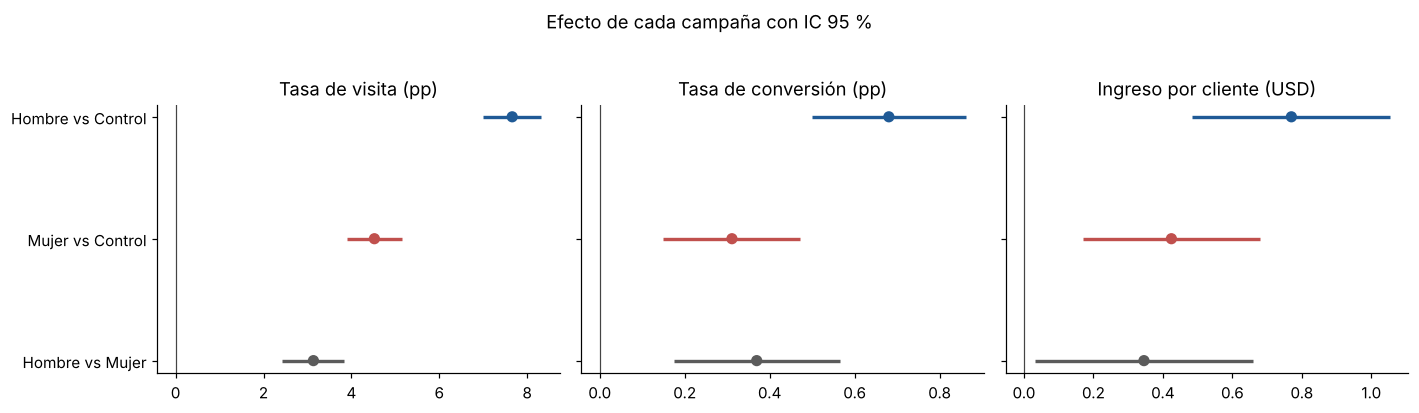

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
titulos = {"visit": "Tasa de visita (pp)", "conversion": "Tasa de conversión (pp)", "spend": "Ingreso por cliente (USD)"}
for ax, (metrica, titulo) in zip(axes, titulos.items()):
    sub = tabla[tabla.metrica == metrica].iloc[::-1]
    escala = 100 if metrica != "spend" else 1
    y = np.arange(len(sub))
    colores = [COLORES["Hombre"] if c.startswith("Hombre vs C") else COLORES["Mujer"] if c.startswith("Mujer") else "#5B5B5B"
               for c in sub.comparacion]
    ax.errorbar(sub.diferencia * escala, y,
                xerr=[(sub.diferencia - sub.ic_inf) * escala, (sub.ic_sup - sub.diferencia) * escala],
                fmt="none", ecolor=colores, elinewidth=2.2, capsize=0)
    ax.scatter(sub.diferencia * escala, y, color=colores, zorder=3, s=40)
    ax.axvline(0, color="#444", lw=0.8)
    ax.set_yticks(y, sub.comparacion if ax is axes[0] else [""] * len(sub))
    ax.set_title(titulo)
    ax.set_xlim(left=min(0, (sub.ic_inf * escala).min()) - 0.05 * (sub.ic_sup * escala).max())
fig.suptitle("Efecto de cada campaña con IC 95 %", y=1.03, fontsize=12)
fig.tight_layout()
fig.savefig(FIGURAS / "02_efectos_principales.png", dpi=150, bbox_inches="tight")

## 3. Confirmación con bootstrap

El ingreso tiene más de 99 % de ceros y cola larga. Para confirmar que el intervalo de Welch no depende de la aproximación normal, repito el cálculo con 10,000 remuestreos bootstrap dentro de cada grupo.

In [5]:
filas = []
distribuciones = {}
for a, b in COMPARACIONES:
    dist = bootstrap_diferencia(df.loc[df.grupo == a, "spend"], df.loc[df.grupo == b, "spend"], n_boot=10_000, semilla=42)
    distribuciones[f"{a} vs {b}"] = dist
    welch = tabla[(tabla.metrica == "spend") & (tabla.comparacion == f"{a} vs {b}")].iloc[0]
    filas.append({
        "comparacion": f"{a} vs {b}",
        "diferencia": welch.diferencia,
        "ic_welch": f"[{welch.ic_inf:.3f}, {welch.ic_sup:.3f}]",
        "ic_bootstrap": f"[{np.percentile(dist, 2.5):.3f}, {np.percentile(dist, 97.5):.3f}]",
        "pct_replicas_<=_0": (dist <= 0).mean(),
    })
pd.DataFrame(filas).set_index("comparacion")

,diferencia,ic_welch,ic_bootstrap,pct_replicas_<=_0
comparacion,,,,
Hombre vs Control,0.769827,"[0.485, 1.055]","[0.482, 1.052]",0.0000
Mujer vs Control,0.424412,"[0.169, 0.680]","[0.172, 0.680]",0.0011
Hombre vs Mujer,0.345415,"[0.033, 0.658]","[0.036, 0.665]",0.0148


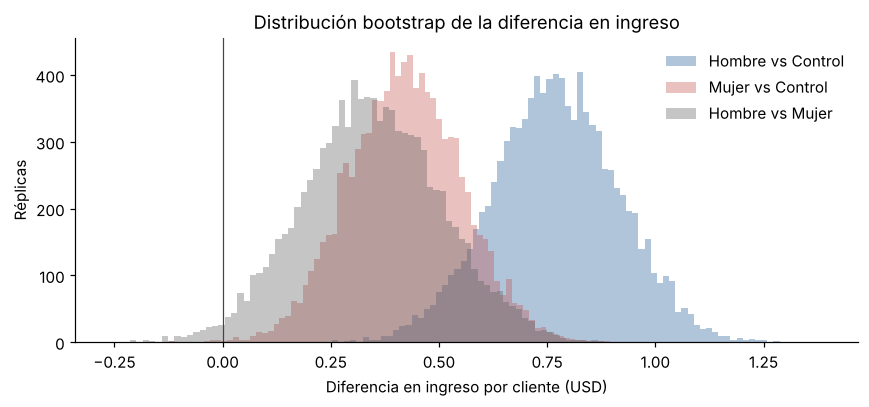

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.8))
paleta = {"Hombre vs Control": COLORES["Hombre"], "Mujer vs Control": COLORES["Mujer"], "Hombre vs Mujer": "#5B5B5B"}
for nombre, dist in distribuciones.items():
    ax.hist(dist, bins=80, histtype="stepfilled", alpha=0.35, color=paleta[nombre], label=nombre)
ax.axvline(0, color="#444", lw=0.8)
ax.set_xlabel("Diferencia en ingreso por cliente (USD)")
ax.set_ylabel("Réplicas")
ax.set_title("Distribución bootstrap de la diferencia en ingreso")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "02_bootstrap_ingreso.png", dpi=150, bbox_inches="tight")

Los intervalos bootstrap difieren de los de Welch en menos de 0.01 USD en cada extremo. Con ~21 mil clientes por grupo, la aproximación normal funciona bien a pesar de la forma del gasto.

## 4. Sensibilidad a valores extremos

El plan proponía repetir el análisis acotando el gasto al percentil 99, pero entre compradores el percentil 99 ya es el máximo (499 USD), así que no cambiaría nada. En su lugar acoto al **percentil 95 de los compradores**. Dejo registrado este cambio respecto al plan.

In [7]:
compradores = df[df.conversion == 1]
tope = compradores.spend.quantile(0.95)
spend_acotado = df.spend.clip(upper=tope)
print(f"Tope (p95 de compradores): {tope:.2f} USD; clientes afectados: {(df.spend > tope).sum()}")

sensibilidad = []
for a, b in COMPARACIONES:
    r = comparar_medias(spend_acotado[df.grupo == a], spend_acotado[df.grupo == b], "spend_acotado", f"{a} vs {b}")
    original = tabla[(tabla.metrica == "spend") & (tabla.comparacion == f"{a} vs {b}")].iloc[0]
    sensibilidad.append({
        "comparacion": f"{a} vs {b}",
        "dif_original": original.diferencia,
        "dif_acotada": r.diferencia,
        "ic_acotado": f"[{r.ic_inf:.3f}, {r.ic_sup:.3f}]",
        "p_valor_acotado": r.p_valor,
    })
pd.DataFrame(sensibilidad).set_index("comparacion").round(4)

Tope (p95 de compradores): 362.20 USD; clientes afectados: 28


,dif_original,dif_acotada,ic_acotado,p_valor_acotado
comparacion,,,,
Hombre vs Control,0.7698,0.7374,"[0.474, 1.000]",0.0000
Mujer vs Control,0.4244,0.4135,"[0.176, 0.651]",0.0007
Hombre vs Mujer,0.3454,0.3240,"[0.034, 0.614]",0.0287


Las conclusiones no dependen de unas pocas compras grandes: los efectos bajan ligeramente y todos siguen siendo significativos.

## 5. ¿De dónde sale el ingreso extra?

El ingreso por cliente es tasa de conversión × ticket promedio. El ticket se calcula solo entre compradores, que es un grupo definido después del envío, así que esta descomposición es **descriptiva**, no causal.

In [8]:
descomp = df.groupby("grupo", observed=True).agg(
    tasa_conversion=("conversion", "mean"),
    compradores=("conversion", "sum"),
    ingreso_por_cliente=("spend", "mean"),
)
descomp["ticket_promedio"] = compradores.groupby("grupo", observed=True)["spend"].mean()
descomp.style.format({"tasa_conversion": "{:.2%}", "compradores": "{:,.0f}",
                      "ingreso_por_cliente": "${:.3f}", "ticket_promedio": "${:.2f}"})

,tasa_conversion,compradores,ingreso_por_cliente,ticket_promedio
grupo,,,,
Control,0.57%,122,$0.653,$114.00
Hombre,1.25%,267,$1.423,$113.53
Mujer,0.88%,189,$1.077,$121.89


El ticket promedio es parecido en los tres grupos (114 a 122 USD). Casi todo el efecto viene de que **más clientes compran**, no de que gasten más por compra.

## Conclusión

- Las dos campañas aumentan visitas, conversiones e ingreso frente a no mandar correo.
- **El correo de hombre es el mejor:** +0.77 USD por cliente frente al control, contra +0.42 del de mujer. La diferencia entre ambos (+0.35 USD) es significativa después del ajuste de Holm (p = 0.03).
- El resultado se sostiene con bootstrap y al acotar valores extremos.
- El efecto viene de más compradores, no de compras más grandes.

Queda la pregunta de si conviene mandar el mismo correo a todos o si hay clientes que responden mejor a cada campaña. Eso se analiza en [`03_segmentos_e_impacto.ipynb`](03_segmentos_e_impacto.ipynb).